# 高雄房價分析：導覽 notebook

這份 notebook 帶你從頭走一遍整個專案：資料長什麼樣子、怎麼清理、SQL 分析、品質調整房價指數、估價模型與誤差分析、以及信用管制的政策分析。
程式邏輯都在 `src/khp/` 裡，這裡只呼叫函式、讀結果、畫圖，方便逐段理解。

**執行前**：先跑過 `python scripts/download_data.py` 與 `python run_pipeline.py`，產生 `data/processed/` 與 `reports/`。
本 notebook 已執行並存下輸出，直接在 GitHub 上看也可以。

| 段落 | 內容 |
|---|---|
| 1 | 資料與清理紀錄 |
| 2 | 資料品質檢查 |
| 3 | SQL 分析（SQLite） |
| 4 | 品質調整房價指數 |
| 5 | 估價模型：比較、誤差分析、SHAP |
| 6 | 政策分析：事件研究與 DiD |
| 7 | 結論與限制 |

In [1]:
import json
import sqlite3
import sys
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import xgboost as xgb

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT / "src"))

from khp import config, plots  # plots sets a CJK font and the chart style
from khp.features import LABELS, add_basic_features, to_model_matrix

pd.set_option("display.max_columns", 30)
pd.set_option("display.width", 160)
%matplotlib inline

## 1. 資料與清理紀錄

原始資料是內政部實價登錄 19 季（111S1–115S3）的高雄成屋買賣檔。`ingest.py` 直接從 zip 讀取，`clean.py` 依序過濾，每一步刪掉多少筆都會記下來。

In [2]:
ingest_log = pd.read_csv(config.REPORTS / "ingest_log.csv")
print(f"{len(ingest_log)} season files, {ingest_log['rows_A'].sum():,} existing-home rows, "
      f"{ingest_log['bad_lines_A'].sum() + ingest_log['bad_lines_B'].sum()} malformed row(s) skipped")
pd.read_csv(config.REPORTS / "cleaning_log.csv")

19 season files, 199,457 existing-home rows, 1 malformed row(s) skipped


,step,rows_after,removed
0,raw Kaohsiung rows (de-duplicated),199457,0
1,keep sales that include a building (drop land-...,160929,38528
2,keep residential building types (大樓/華廈/公寓/透天厝/套房),160882,47
3,keep single-building deals (建物 = 1),159665,1217
4,trade date on/after 2022-01-01,128684,30981
5,drop special / non-arm's-length deals flagged ...,113248,15436
6,drop units whose main use is commercial / indu...,110383,2865
7,valid area (5–300 坪 excl. parking) and price (...,110098,285
8,drop unit-price outliers (|robust z| > 3.5 wit...,108063,2035


刪除最多的是「不含建物的交易」（純土地、純車位）和 2022 年以前的資料，這些都是範圍設定。
真正需要判斷的是**特殊交易**：備註裡的親友交易、瑕疵、法拍等會影響價格，所以刪掉；但「增建、頂樓加蓋」在高雄透天厝非常普遍，是正常的市場交易，所以保留並加上 `has_addition` 特徵，而不是刪除。

In [3]:
clean = pd.read_parquet(config.CLEAN_PARQUET)
print(f"clean deals: {len(clean):,}  ({clean['trade_date'].min():%Y-%m} to {clean['trade_date'].max():%Y-%m})")
(clean.groupby("btype")
      .agg(deals=("serial", "size"),
           median_unit_price=("unit_price", "median"),
           share_with_addition=("has_addition", "mean"))
      .round(3)
      .sort_values("deals", ascending=False))

clean deals: 108,063  (2022-01 to 2026-08)


,deals,median_unit_price,share_with_addition
btype,,,
大樓,62237,31.513,0.036
透天厝,23598,27.351,0.452
華廈,12475,22.717,0.064
公寓,9753,16.395,0.265


約 45% 的透天厝備註有增建。如果照原本的規則刪掉，透天厝樣本會少一半，模型和房價指數都會偏向沒有增建的物件。

## 2. 資料品質檢查

模擬資料測不出來、只有真實資料才看得到的問題：地址遮蔽後還能不能解析路名、單價分布是否合理、缺值比例。

In [4]:
checks = pd.Series({
    "road name parsed": clean["road"].notna().mean(),
    "building age missing": clean["age_years"].isna().mean(),
    "parking not priced separately (of deals with parking)": clean.loc[clean["has_parking"] == 1, "parking_unpriced"].mean(),
    "unit price within 15–45 (萬/坪)": clean["unit_price"].between(15, 45).mean(),
})
checks.map("{:.1%}".format).to_frame("share")

,share
road name parsed,98.9%
building age missing,0.9%
parking not priced separately (of deals with parking),46.3%
unit price within 15–45 (萬/坪),85.7%


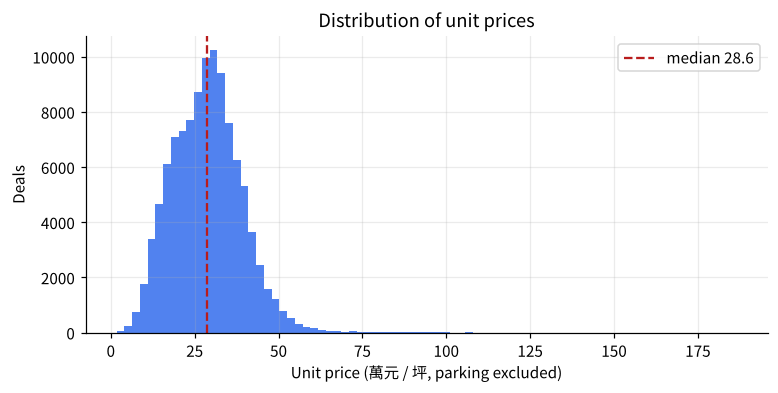

In [5]:
fig, ax = plt.subplots(figsize=(8, 3.5))
ax.hist(clean["unit_price"], bins=80, color=plots.BLUE, alpha=0.8)
ax.axvline(clean["unit_price"].median(), color=plots.RED, ls="--", label=f"median {clean['unit_price'].median():.1f}")
ax.set(xlabel="Unit price (萬元 / 坪, parking excluded)", ylabel="Deals", title="Distribution of unit prices")
ax.legend();

路名解析失敗的大多是只有「○○巷」沒有路／街名的地址，比例不到 1%，這些物件在估價時會退回用行政區平均。

In [6]:
clean.loc[clean["road"].isna(), "address"].head(5).tolist()

['高雄市仁武區和平巷３之６號',
 '高雄市前鎮區台鋁十一巷１６號三樓',
 '高雄市內門區東勢埔１號',
 '高雄市仁武區仁勇西巷５號',
 '高雄市仁武區大義巷４５號']

## 3. SQL 分析（SQLite）

清理後的資料寫進 SQLite，`sql/` 有 6 支查詢。SQLite 沒有 `MEDIAN()`，所以用視窗函數算中位數。下面直接執行其中一支：各行政區每季單價中位數與年增率（`LAG(…, 4)`）。

In [7]:
query = (ROOT / "sql" / "12_district_quarterly_yoy.sql").read_text(encoding="utf-8")
print(query)

-- District x quarter median unit price, with year-over-year change via LAG().
WITH ranked AS (
    SELECT district, quarter, unit_price,
           ROW_NUMBER() OVER (PARTITION BY district, quarter ORDER BY unit_price) AS rn,
           COUNT(*)     OVER (PARTITION BY district, quarter)                     AS cnt
    FROM transactions
),
q AS (
    SELECT district, quarter, MAX(cnt) AS deals, AVG(unit_price) AS median_unit_price
    FROM ranked
    WHERE rn IN ((cnt + 1) / 2, (cnt + 2) / 2)
    GROUP BY district, quarter
)
SELECT *
FROM (
    SELECT district,
           quarter,
           deals,
           ROUND(median_unit_price, 2) AS median_unit_price,
           ROUND(100.0 * (median_unit_price
                 / LAG(median_unit_price, 4) OVER (PARTITION BY district ORDER BY quarter) - 1), 1) AS yoy_pct
    FROM q
)
WHERE deals >= 20   -- filter after LAG() so the 4-quarter offset is not shifted
ORDER BY district, quarter;



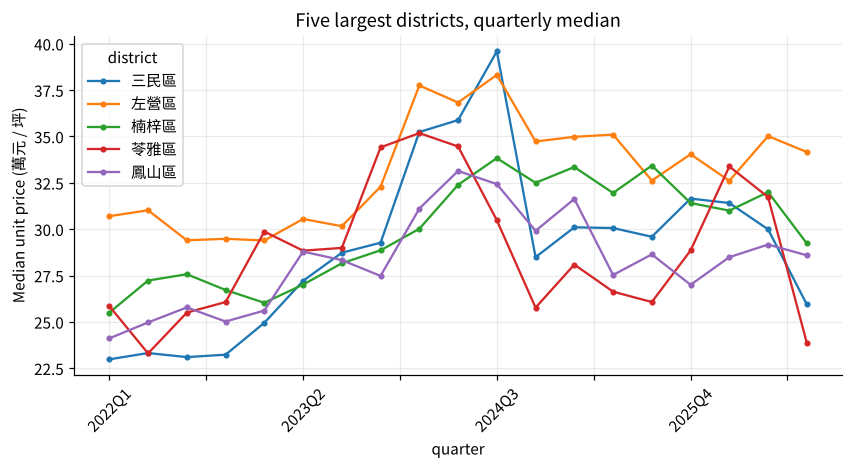

In [8]:
with sqlite3.connect(config.DATA_PROCESSED / "kaohsiung.db") as con:
    yoy = pd.read_sql(query, con)

big = ["三民區", "鳳山區", "左營區", "楠梓區", "苓雅區"]
pivot = yoy[yoy["district"].isin(big)].pivot(index="quarter", columns="district", values="median_unit_price")
ax = pivot.plot(figsize=(9, 4), marker="o", ms=3)
ax.set(ylabel="Median unit price (萬元 / 坪)", title="Five largest districts, quarterly median")
ax.tick_params(axis="x", rotation=45);

## 4. 品質調整房價指數

單價中位數會受到「這個月賣的是什麼房子」影響。特徵價格模型（hedonic regression）用 log 單價對物件特徵、行政區與**月份固定效果**回歸，月份效果就是控制品質後的價格變化。

peak 2024-09: hedonic index 130.8 (raw median index 133.8)


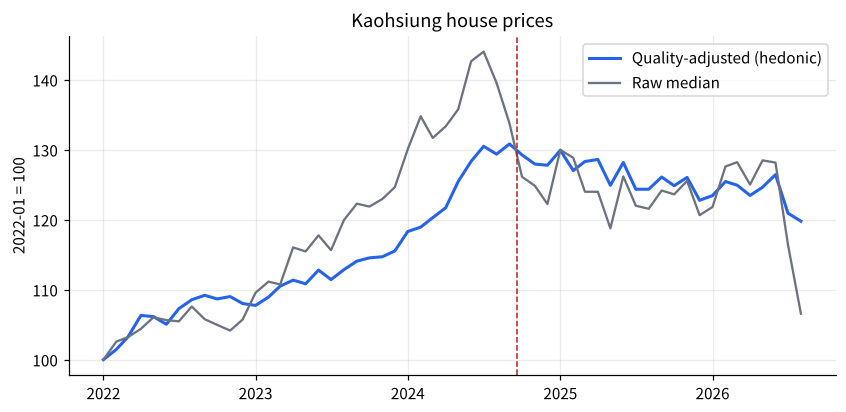

In [9]:
idx = pd.read_csv(config.REPORTS / "hedonic_price_index.csv")
peak = idx.loc[idx["hedonic_index"].idxmax()]
print(f"peak {peak['ym']}: hedonic index {peak['hedonic_index']:.1f} (raw median index {peak['median_index']:.1f})")

fig, ax = plt.subplots(figsize=(9, 4))
ax.plot(pd.to_datetime(idx["ym"]), idx["hedonic_index"], color=plots.BLUE, lw=2, label="Quality-adjusted (hedonic)")
ax.plot(pd.to_datetime(idx["ym"]), idx["median_index"], color=plots.GREY, label="Raw median")
ax.axvline(config.POLICY_EVENTS["wave7"], color=plots.RED, ls="--", lw=1)
ax.set(ylabel="2022-01 = 100", title="Kaohsiung house prices")
ax.legend();

2024 年上半年中位數漲得比品質調整指數多很多，因為那段時間大量新成屋交屋（新房單價高），是「組成效果」不是同一間房子變貴。
注意：最後兩個月的交易還沒登錄完整，數字僅供參考。

主要係數（`pct_effect` = 對單價的百分比影響，標準誤以行政區為 cluster）：

In [10]:
coefs = pd.read_csv(config.REPORTS / "hedonic_coefficients.csv", index_col=0)
coefs.loc[["log_area", "age_years", "has_parking", "parking_unpriced", "has_addition",
           "C(btype)[T.大樓]", "C(btype)[T.透天厝]"], ["coef", "se", "p_value", "pct_effect"]]

,coef,se,p_value,pct_effect
log_area,-0.2561,0.0201,0.0000,-22.5972
age_years,-0.0291,0.0015,0.0000,-2.8729
has_parking,0.0373,0.0119,0.0017,3.8009
parking_unpriced,0.1243,0.0103,0.0000,13.2343
has_addition,0.0789,0.0084,0.0000,8.2108
C(btype)[T.大樓],0.3719,0.0313,0.0000,45.0477
C(btype)[T.透天厝],0.1898,0.0149,0.0000,20.8987


## 5. 估價模型

### 5.1 時間切分與模型比較

用過去預測未來：train 到 2025-06、validation 2025 下半年（調參與 early stopping）、test 是 2026 年的交易，只在最後評估一次。誤差以**總價**計算。

In [11]:
pd.read_csv(config.REPORTS / "model_comparison.csv", index_col=0)

,MAPE_%,MdAPE_%,within_10%,within_20%,R2_log_unit_price,n
model,,,,,,
Baseline: district × type median,30.07,18.94,29.7,52.0,0.311,8102.0
"Hedonic OLS (+ road level, trend)",21.13,14.01,37.9,64.4,0.630,8102.0
XGBoost,13.27,8.87,54.9,80.3,0.798,8102.0


XGBoost 的誤差中位數（MdAPE）比特徵價格 OLS 低約 5 個百分點。OLS 的好處是係數可以解釋，所以兩個模型分工：OLS 用來解釋與建立指數，XGBoost 用來估價。

### 5.2 誤差分析：哪些物件比較難估？

整體數字會掩蓋問題，所以把測試期的誤差按型態與價格高低拆開看。

In [12]:
test = pd.read_parquet(config.REPORTS / "test_predictions.parquet")
test["ape"] = (test["pred_unit_price"] / test["unit_price"] - 1).abs()   # area cancels: same as total-price error
test["signed_err"] = test["pred_unit_price"] / test["unit_price"] - 1

by_type = (test.groupby("btype")
               .agg(deals=("ape", "size"), MdAPE=("ape", "median"),
                    within_10=("ape", lambda s: (s <= 0.10).mean()),
                    median_bias=("signed_err", "median"))
               .sort_values("deals", ascending=False))
by_type.style.format({"MdAPE": "{:.1%}", "within_10": "{:.1%}", "median_bias": "{:+.1%}"})

,deals,MdAPE,within_10,median_bias
btype,,,,
大樓,4510,7.1%,64.9%,-0.2%
透天厝,1866,14.0%,37.9%,-1.1%
華廈,969,7.5%,60.1%,+0.5%
公寓,757,15.9%,31.0%,+3.1%


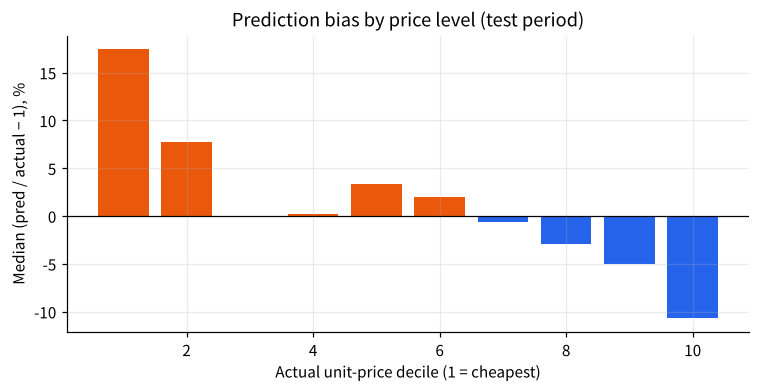

In [13]:
test["price_decile"] = pd.qcut(test["unit_price"], 10, labels=False) + 1
dec = test.groupby("price_decile").agg(MdAPE=("ape", "median"), bias=("signed_err", "median"))

fig, ax = plt.subplots(figsize=(8, 3.5))
ax.bar(dec.index, 100 * dec["bias"], color=[plots.ORANGE if b > 0 else plots.BLUE for b in dec["bias"]])
ax.axhline(0, color="black", lw=0.8)
ax.set(xlabel="Actual unit-price decile (1 = cheapest)", ylabel="Median (pred / actual − 1), %",
       title="Prediction bias by price level (test period)");

大樓與華廈的誤差中位數約 7%，透天厝與公寓約 14–16%，明顯比較難估：透天厝的土地、增建、屋況差異大，老公寓則多半是看土地與都更題材。

典型的「往平均值收縮」：最便宜的物件被高估、最貴的被低估。原因是模型看不到的特徵（景觀、裝潢、屋況、是否急售）在兩端最重要。
這也是為什麼 app 會給 80% 預測區間，而不只給一個數字。

### 5.3 SHAP：模型用了哪些資訊？

用 XGBoost 內建的 `pred_contribs`（TreeSHAP）算每個特徵對每筆預測的貢獻。這裡用的是最終模型（用全部資料訓練、app 使用的那一個）。

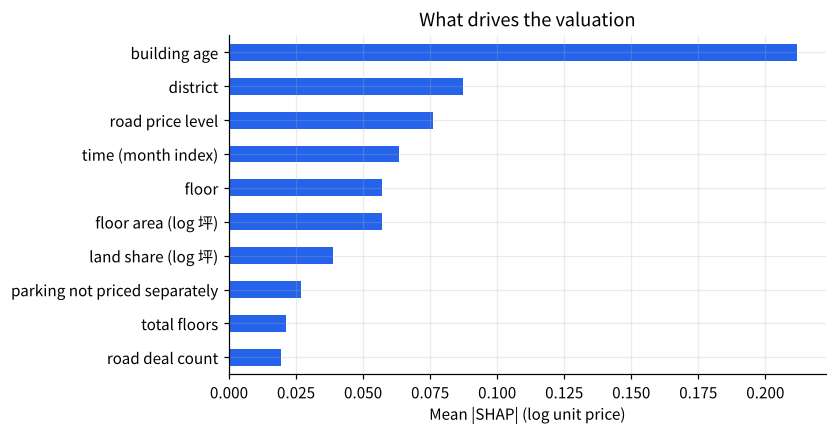

In [14]:
booster = xgb.Booster()
booster.load_model(ROOT / "models" / "xgb_unit_price.json")
meta = json.loads((ROOT / "models" / "metadata.json").read_text(encoding="utf-8"))

from khp.features import RoadEncoder
sample = add_basic_features(clean[clean["district"].isin(meta["categories"]["district"])].dropna(subset=["age_years"]))
sample = sample.sample(3000, random_state=0)
sample = RoadEncoder().fit_transform(sample)          # road level feature (out-of-fold)
X = to_model_matrix(sample, meta["categories"])
contribs = booster.predict(xgb.DMatrix(X, enable_categorical=True), pred_contribs=True)[:, :-1]

importance = (pd.Series(np.abs(contribs).mean(axis=0), index=meta["features"])
                .rename(LABELS).sort_values())
ax = importance.tail(10).plot.barh(figsize=(7, 4), color=plots.BLUE)
ax.set(xlabel="Mean |SHAP| (log unit price)", title="What drives the valuation");

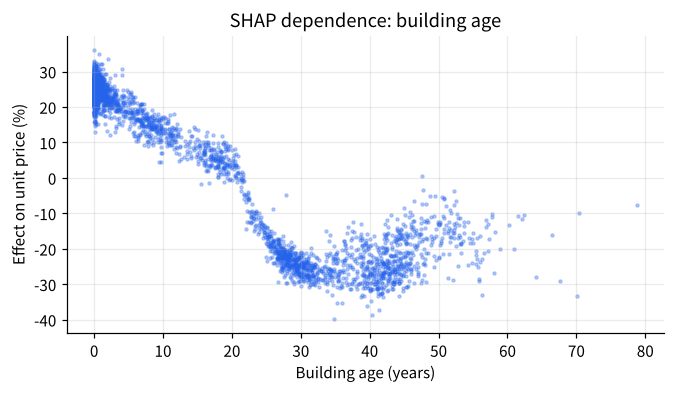

In [15]:
age = pd.DataFrame({"age": X["age_years"], "shap": contribs[:, meta["features"].index("age_years")]})
fig, ax = plt.subplots(figsize=(7, 3.5))
ax.scatter(age["age"], 100 * (np.exp(age["shap"]) - 1), s=4, alpha=0.3, color=plots.BLUE)
ax.set(xlabel="Building age (years)", ylabel="Effect on unit price (%)", title="SHAP dependence: building age");

屋齡是最重要的因素：從新成屋到屋齡 30 年左右，單價的影響從約 +25% 一路降到約 −25%；30 年以後不再往下，40 年以上甚至回升。老公寓的價格主要反映土地持分與都更潛力，而不是建物本身。

## 6. 政策分析：2024 年 9 月信用管制

**問題**：第七波選擇性信用管制（2024-09-20）主要限制第二屋與投資客。這類買家比較常買小坪數，所以比較「小坪數（套房、1–2 房）」和「家庭型（3 房以上）」在管制前後的價格與交易量差異。

**事件研究**：把「小坪數 × 每一季」放進回歸（基期 2024Q2），可以同時看管制前（pre-trend）和管制後的差異。

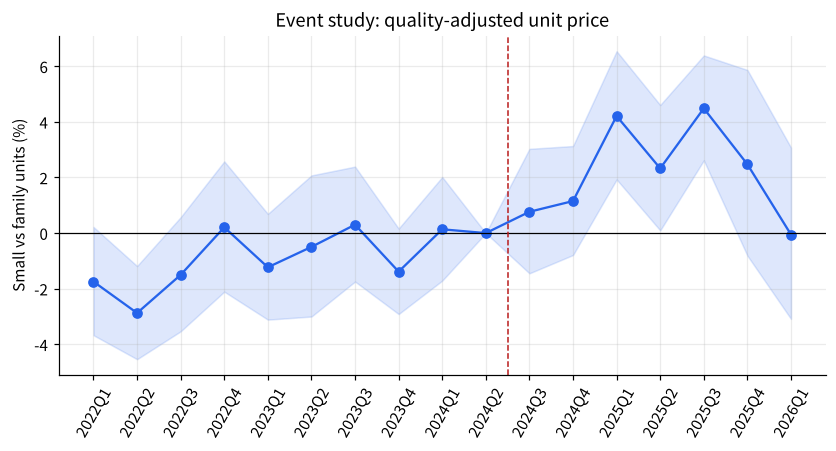

In [16]:
es = pd.read_csv(config.REPORTS / "policy" / "event_study_price.csv")
fig, ax = plt.subplots(figsize=(9, 4))
ax.fill_between(es["rel"], es["ci_low"], es["ci_high"], color=plots.BLUE, alpha=0.15)
ax.plot(es["rel"], es["pct"], marker="o", color=plots.BLUE)
ax.axhline(0, color="black", lw=0.8)
ax.axvline(-0.5, color=plots.RED, ls="--", lw=1)
ax.set_xticks(es["rel"], es["quarter"], rotation=60)
ax.set(ylabel="Small vs family units (%)", title="Event study: quality-adjusted unit price");

In [17]:
summary = json.loads((config.REPORTS / "policy" / "did_summary.json").read_text(encoding="utf-8"))
rows = {
    "Price DiD": summary["price_did_small_x_post"],
    "Price DiD, trend-adjusted": summary["price_did_trend_adjusted"],
    "Volume DiD (PPML)": summary["volume_did_small_x_post"],
}
table = pd.DataFrame({k: {"effect_%": v["pct_effect"], "ci95_%": v["ci95_pct"], "p_value": v["p_value"]}
                      for k, v in rows.items()}).T
table.loc["Price DiD", "wild bootstrap p"] = summary["price_did_small_x_post"]["wild_cluster_bootstrap"]["p_value"]
table

,effect_%,ci95_%,p_value,wild bootstrap p
Price DiD,3.2,"[2.0, 4.4]",0.0,0.007
"Price DiD, trend-adjusted",1.7,"[-0.3, 3.7]",0.0955,NaN
Volume DiD (PPML),-1.8,"[-17.3, 16.4]",0.831,NaN


In [18]:
pd.DataFrame({k: summary[k] for k in ["price_pretrend_test", "volume_pretrend_test"]}).T

,pre_period_dummies,wald_chi2,p_value_chi2,F,df,p_value_F
price_pretrend_test,9,52.77,0.0,5.86,"[9, 29]",0.00012
volume_pretrend_test,9,17.56,0.040622,1.95,"[9, 21]",0.099457


**解讀**

1. 單純 DiD：小坪數價格在管制後相對上漲 3.2%，wild cluster bootstrap 下仍然顯著。
2. 但事件研究圖顯示小坪數在**管制前就已經一路追上來**，pre-trend 的聯合 F 檢定強烈拒絕（p≈0.0001），平行趨勢假設不成立。
3. 加入「小坪數 × 線性時間趨勢」後，效果剩 1.7% 且不顯著（p≈0.10）。交易量則一直沒有顯著差異。

**結論：沒有穩健證據顯示信用管制對小坪數有差異效果。**

**為什麼要做 wild cluster bootstrap？** 標準誤以行政區為 cluster，但只有 30 個行政區。cluster 數少時，一般的 cluster-robust 檢定容易過度拒絕。
Wild cluster restricted bootstrap 在虛無假設成立下重抽「整個行政區的殘差正負號」（Webb 六點權重），用模擬出來的 t 分布算 p 值。實作在 `policy.wild_cluster_bootstrap`，大約 40 行 numpy。

In [19]:
from khp import policy
import inspect
print(inspect.getsource(policy.wild_cluster_bootstrap))

def wild_cluster_bootstrap(formula: str, data: pd.DataFrame, param: str, cluster: str,
                           reps: int = 999, seed: int = config.RANDOM_STATE) -> dict:
    """Wild cluster restricted bootstrap p-value for H0: param = 0.

    1. Fit the model with the null imposed (param dropped) -> fitted values and residuals.
    2. For each replication, flip every cluster's residuals by one Webb weight,
       rebuild y*, re-estimate the full model and its cluster-robust t-stat.
    3. p-value = share of bootstrap |t*| at least as large as the observed |t|.

    The full-model OLS is solved once with a pseudo-inverse, so each replication
    is just a matrix-vector product.
    """
    import patsy

    y, X = patsy.dmatrices(formula, data, return_type="dataframe")
    j = list(X.columns).index(param)
    groups = pd.factorize(data.loc[X.index, cluster])[0]
    G = groups.max() + 1
    X, y = X.to_numpy(), y.to_numpy().ravel()
    n, k = X.shape

    pinv = np.linalg.pinv(X)     

## 7. 結論與限制

- **資料**：19.9 萬筆原始紀錄清理成 10.8 萬筆，每一步都有紀錄；檢查真實資料後修正了「增建被當成特殊交易」的規則。
- **房價**：品質調整後，高雄房價 2022-01 到 2024-09 上漲約 31%，之後持平微跌。
- **估價**：XGBoost 在 2026 年的測試資料上總價誤差中位數 8.9%，80% 在 ±20% 內；最便宜與最貴的物件有往平均收縮的偏誤。
- **政策**：沒有穩健的差異效果；平行趨勢不成立是關鍵。

**限制**

- 實價登錄沒有屋況、裝潢、景觀等資訊，這是估價誤差的主要來源。
- 政策分析只能估兩組之間的「差異效果」，兩組都受到的衝擊（銀行房貸總量控管、整體降溫）會被固定效果吸收。
- 用房數分群是買家類型的代理變數；線性趨勢調整本身也是假設。